## Import

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tqdm import tqdm
import numpy as np
import pandas as pd
import re
import string
from matplotlib import pyplot as plt
import keras
keras.utils.set_random_seed(42)


# from tensorflow.keras.preprocessing.text import Tokenizer

from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Embedding, GRU, LSTM, Dense, Input, Dropout
from keras.optimizers import Adam
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping


import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

import sys
sys.path.append("..")
from utils.preprocessing import LABELS, encode_labels, fit_tokenizer, encode_texts, clean_text

from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


Baseline models for 3-class sentiment (negative / neutral / positive) on Financial PhraseBank. Trained on train.csv, evaluated on val.csv. Main metric: macro F1, because the classes are imbalanced (59% neutral, 12% negative), so accuracy alone would reward a model that ignores negatives.



In [2]:
metrics = pd.read_csv("../results/metrics.csv")
metrics

,condition,embedding_config,architecture,accuracy_overall,f1_overall,accuracy_hard,f1_hard,accuracy_nonhard,f1_nonhard,f1_negative,f1_neutral,f1_positive
0,baseline,tfidf_1-2gram,logreg,0.776629,0.717241,NaN,NaN,NaN,NaN,0.631579,0.845771,0.674374
1,baseline,random_init_100d,lstm_64_dropout,0.698035,0.464626,NaN,NaN,NaN,NaN,0.000000,0.832653,0.561224


In [3]:
train = pd.read_csv("../data/train.csv")
val = pd.read_csv("../data/val.csv")

### Preprocessing


In [4]:
print(clean_text(train.sentence[0]))     


the fair value of the company 's investment properties went down to eur <num> billion at the end of <num> from eur <num> billion a year earlier .


Our preprocessing pipeline cleans each sentence in two steps: it lowercases all words and replaces every number with a <num> placeholder. Replacing numbers has been shown to improve sentiment classification (Symeonidis et al., 2018). The sentiment of a sentence depends on its structure, such as "profit rose to <num>", rather than on the exact figure. This also reduces the vocabulary from 7,840 to 7,081 words.

We do not remove stopwords e.g. standard lists such as NLTK's include words like not, down and up, which carry the sentiment in financial text. The tokenizer is fitted on the training set only, to avoid information leaking from the validation set.


In [5]:
### Encode the labels as {negative: 0, neutral: 1, positive: 2}
y_train = encode_labels(train.label)
y_val = encode_labels(val.label)

### First Baseline (Tfidf vectorizer + Logistic Regression)

In [6]:
vec = TfidfVectorizer(
    preprocessor=clean_text,  
    tokenizer=str.split,       
    token_pattern=None,
    ngram_range=(1, 2),
    sublinear_tf=True,           
)
X_train_tfidf = vec.fit_transform(train.sentence)   # fit on train only
X_val_tfidf = vec.transform(val.sentence)

In [7]:
clf = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
clf.fit(X_train_tfidf, y_train)


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to 

accuracy: 0.7766287487073423
macro F1: 0.7172412958027023
              precision    recall  f1-score   support

    negative       0.75      0.55      0.63       121
     neutral       0.81      0.89      0.85       574
    positive       0.71      0.64      0.67       272

    accuracy                           0.78       967
   macro avg       0.76      0.69      0.72       967
weighted avg       0.77      0.78      0.77       967



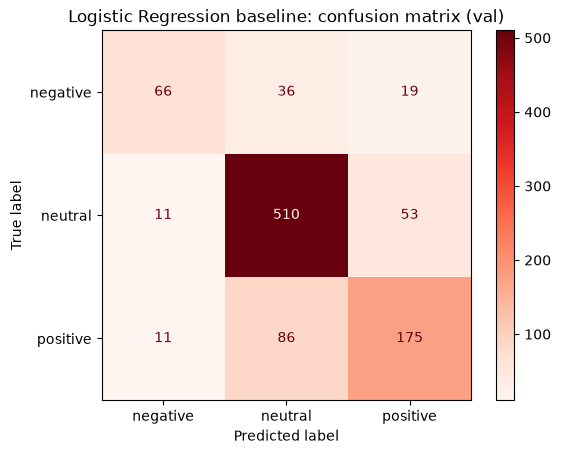

In [8]:
pred_lr = clf.predict(X_val_tfidf)
print("accuracy:", accuracy_score(y_val, pred_lr))
print("macro F1:", f1_score(y_val, pred_lr, average="macro"))
print(classification_report(y_val, pred_lr, target_names=LABELS))
disp = ConfusionMatrixDisplay.from_predictions(
    y_val, pred_lr, display_labels=LABELS, cmap="Reds")
disp.ax_.set_title("Logistic Regression baseline: confusion matrix (val)")
plt.show()

Classical baseline. Unigrams + bigrams so phrases like "went down" count as one 'bucket'


### Second baseline

In [9]:

tok = fit_tokenizer(train.sentence)   
   
X_train = encode_texts(tok, train.sentence)
X_val = encode_texts(tok, val.sentence)
y_train = encode_labels(train.label)
y_val = encode_labels(val.label)

vocab_size = len(tok.word_index) + 1
print(X_train.shape, X_val.shape, vocab_size)   # expect (2901, 64) (967, 64) ~7081


(2901, 64) (967, 64) 7081


In [10]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Embedding(vocab_size, 100, mask_zero=True),  
    LSTM(64),
    Dropout(0.3),
    Dense(len(LABELS), activation="softmax"),
])
model.compile(optimizer=Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 64, 100)        │       708,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 750,535 (2.86 MB)

 Trainable params: 750,535 (2.86 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    X_train, to_categorical(y_train, len(LABELS)),
    validation_data=(X_val, to_categorical(y_val, len(LABELS))),
    epochs=30, batch_size=32,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)


Epoch 1/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.6119 - loss: 0.8793 - val_accuracy: 0.6836 - val_loss: 0.7758
Epoch 2/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7449 - loss: 0.5760 - val_accuracy: 0.6980 - val_loss: 0.7542
Epoch 3/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.8600 - loss: 0.3610 - val_accuracy: 0.7322 - val_loss: 0.7804
Epoch 4/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9369 - loss: 0.1910 - val_accuracy: 0.7032 - val_loss: 0.8653
Epoch 5/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9669 - loss: 0.1243 - val_accuracy: 0.6939 - val_loss: 1.0851


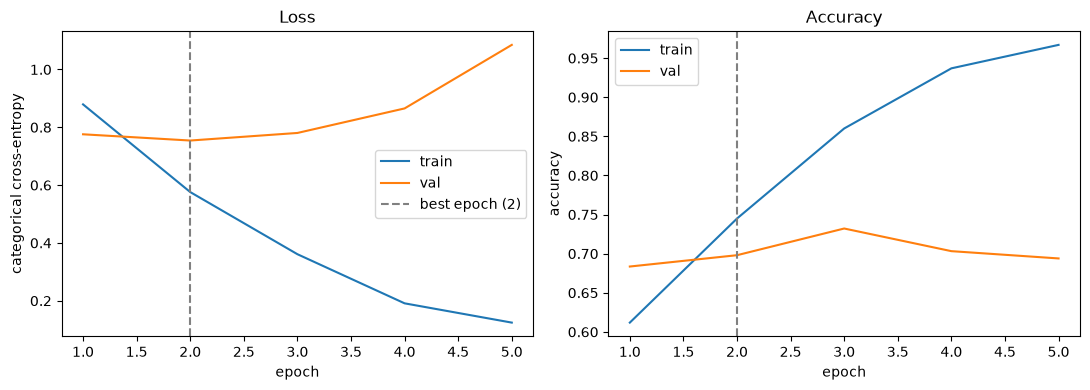

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
epochs = range(1, len(history.history["loss"]) + 1)
best = int(np.argmin(history.history["val_loss"])) + 1   # epoch whose weights EarlyStopping restored

ax1.plot(epochs, history.history["loss"], label="train")
ax1.plot(epochs, history.history["val_loss"], label="val")
ax1.axvline(best, color="grey", linestyle="--", label=f"best epoch ({best})")
ax1.set(title="Loss", xlabel="epoch", ylabel="categorical cross-entropy")
ax1.legend()

ax2.plot(epochs, history.history["accuracy"], label="train")
ax2.plot(epochs, history.history["val_accuracy"], label="val")
ax2.axvline(best, color="grey", linestyle="--")
ax2.set(title="Accuracy", xlabel="epoch", ylabel="accuracy")
ax2.legend()

plt.tight_layout()
plt.savefig("../results/baseline_lstm_loss.png", dpi=150)
plt.show()


31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
accuracy: 0.6980351602895554
macro F1: 0.4646258503401361
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       121
     neutral       0.78      0.89      0.83       574
    positive       0.52      0.61      0.56       272

    accuracy                           0.70       967
   macro avg       0.44      0.50      0.46       967
weighted avg       0.61      0.70      0.65       967



/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zer

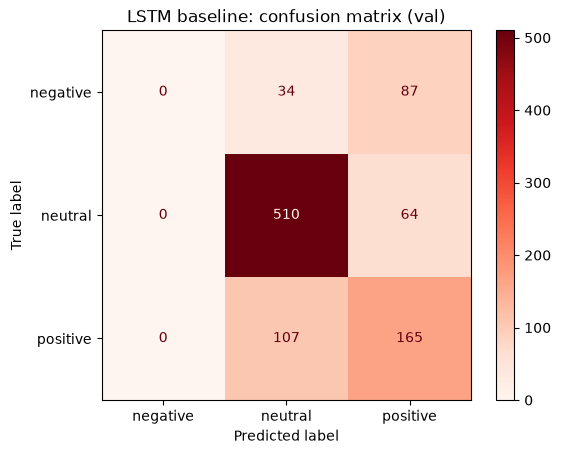

In [13]:
pred_lstm = model.predict(X_val).argmax(axis=1)
print("accuracy:", accuracy_score(y_val, pred_lstm))
print("macro F1:", f1_score(y_val, pred_lstm, average="macro"))
print(classification_report(y_val, pred_lstm, target_names=LABELS))
disp = ConfusionMatrixDisplay.from_predictions(
    y_val, pred_lstm, display_labels=LABELS, cmap="Reds")
disp.ax_.set_title("LSTM baseline: confusion matrix (val)")
plt.show()

In [14]:
def make_row(embedding_config, architecture, pred):
    f1_neg, f1_neu, f1_pos = f1_score(y_val, pred, average=None)
    return {"condition": "baseline", "embedding_config": embedding_config, "architecture": architecture,
            "accuracy_overall": accuracy_score(y_val, pred), "f1_overall": f1_score(y_val, pred, average="macro"),
            "f1_negative": f1_neg, "f1_neutral": f1_neu, "f1_positive": f1_pos}

rows = [make_row("tfidf_1-2gram", "logreg", pred_lr),
        make_row("random_init_100d", "lstm_64_dropout", pred_lstm)]
metrics = pd.concat([metrics, pd.DataFrame(rows)], ignore_index=True)
metrics.to_csv("../results/metrics.csv", index=False)
metrics

,condition,embedding_config,architecture,accuracy_overall,f1_overall,accuracy_hard,f1_hard,accuracy_nonhard,f1_nonhard,f1_negative,f1_neutral,f1_positive
0,baseline,tfidf_1-2gram,logreg,0.776629,0.717241,NaN,NaN,NaN,NaN,0.631579,0.845771,0.674374
1,baseline,random_init_100d,lstm_64_dropout,0.698035,0.464626,NaN,NaN,NaN,NaN,0.000000,0.832653,0.561224
2,baseline,tfidf_1-2gram,logreg,0.776629,0.717241,NaN,NaN,NaN,NaN,0.631579,0.845771,0.674374
3,baseline,random_init_100d,lstm_64_dropout,0.698035,0.464626,NaN,NaN,NaN,NaN,0.000000,0.832653,0.561224


In [15]:
import os
os.makedirs("../results/probs", exist_ok=True)

def save_probs(probs, name):
    out = val[["sentence", "label"]].copy()
    out[["p_negative", "p_neutral", "p_positive"]] = probs
    out["p_true"] = probs[np.arange(len(val)), y_val]
    out["pred"] = [LABELS[i] for i in probs.argmax(axis=1)]
    out.to_csv(f"../results/probs/{name}_val.csv", index=False)

save_probs(clf.predict_proba(X_val_tfidf), "baseline_logreg")
save_probs(model.predict(X_val), "baseline_lstm")

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [16]:
import statistics
lengths = list(val.sentence.str.split().str.len())
print(f"Sentence median length: {statistics.median(lengths)}")


Sentence median length: 21


TF-IDF + LR outperforms the LSTM. The most likely cause is data size. The LSTM's 750k parameters are learned from 2,901 sentences, and it overfits after ~2 epochs. Sentences are also short (median 21 words), which limits the benefit of modelling word order.

## Model Saving

In [17]:
import pickle, os
os.makedirs("../models", exist_ok=True)

In [18]:
model.save("../models/baseline_lstm.keras")

In [19]:
for obj, name in [(tok, "baseline_lstm_tokenizer"), (vec, "baseline_tfidf_vectorizer"), (clf, "baseline_logreg")]:
    with open(f"../models/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)